# Classification of BRACS slides from UNI2-h embeddings

**Goal.** Train a PyTorch classifier that assigns each whole-slide image to one of the seven BRACS classes (N, PB, UDH, FEA, ADH, DCIS, IC) from the tile embeddings extracted in `01_wsi_to_vectors.ipynb`, and evaluate it with a complete set of metrics on the official Testing set.

**Approach.** A slide is a bag of tile embeddings with a single label (multiple-instance learning; the bag is defined in section 3.2). Labels are not available for individual tiles, and a slide label is only the highest-grade region of the slide, so the unit of learning is the slide. Two models are trained and their results are shown side by side: a **gated attention multiple-instance model** (ABMIL, Ilse et al., 2018) that learns how much each tile contributes to the slide representation, and **CLAM-MB** (clustering-constrained attention multiple-instance learning, multi-branch; Lu et al., 2021), which learns one attention branch per class and adds an instance-level clustering loss on the tiles that the attention selects. The difference between them measures what the class-wise attention and the clustering loss add.

**Pipeline.**
1. **Setup**: library versions, compute device and imports.
2. **Parameters**: paths, seeds and training settings.
3. **Data**: the official split, the bags of tile embeddings and the class weights.
4. **Models**: gated ABMIL and CLAM-MB.
5. **Training**: patient-grouped cross-validation folds over the Training and Validation slides; choice of the loss weighting, the regularisation (dropout, weight decay, tile dropout) and a coarse auxiliary loss by cross-validation; training of the fold models of both architectures.
6. **Evaluation on the Testing set**: confusion matrices, ROC and precision-recall curves, F1, calibration, clinical summaries and a paired comparison of the two models.
7. **Interpretation**: attention of both models over the tiles of selected slides.
8. **Summary and export**.

**Protocol.** The official Testing set of BRACS is used unchanged and only once, in section 6, after all choices are fixed. The official Training and Validation slides are pooled and split into patient-grouped, class-stratified folds; every choice (loss weighting, regularisation, coarse loss, epoch) is made by cross-validation on this pool, and a model never sees the labels of the slides on which it is scored. The code enforces that Testing slides never enter training or selection.

**Inputs / outputs.** Inputs: the per-slide `.pt` feature files in `FEATURES_DIR/<model>/` and `labels/BRACS.xlsx`. Results (tables and figures) are shown in the notebook and are not written to disk. The only output file is the best classifier, `classifier/classifier_model_<date-time>.pt`, with its weights, class names, feature scaler, settings and early-stopping result.

**Reproducibility.** One `SEED` fixes every random choice (initialisation, batch order, tile subsampling, bootstrap); every fold is trained with several repeats (consecutive seeds) and the results are reported for the average of the probabilities of the fold models and for the single models. The code is device-agnostic: it runs on a GPU when one is available and on the CPU otherwise. Library versions, device and all settings are printed here and saved in `config.json`.

**Overview.** Flow of this notebook (sections, functions and files).

```mermaid
flowchart TD
    subgraph IN["Inputs"]
        FEAT[("FEATURES_DIR/UNI2-h/<br/>one .pt file per slide (from 01)")]
        LAB[("labels/BRACS.xlsx<br/>class, patient, official set")]
    end

    subgraph S3["3. Data"]
        D1["3.1 build_slide_table<br/>official split"]
        D2["3.2 load_bags<br/>bag of tile embeddings per slide"]
        D3["3.3 plot_bag_sizes"]
        D4["3.4 class weights<br/>from Training only"]
    end

    subgraph S4["4. Models"]
        M1["gated attention MIL<br/>(ABMIL)"]
        M2["CLAM-MB<br/>class-wise attention + instance loss"]
    end

    subgraph S5["5. Training (Training + Validation, cross-validated)"]
        F0["5.0 make_cv_folds<br/>patient-grouped, stratified"]
        T1["5.1 cv_compare<br/>loss weighting"]
        T1b["5.2 cv_compare<br/>dropout, weight decay, tile dropout"]
        T1c["5.3 cv_compare<br/>coarse tier loss"]
        T2["5.4 cross_validate<br/>fold models, early stopping inside each fold"]
        T2b["5.5 out-of-fold performance"]
        T3["5.6 plot_training_curves"]
    end

    subgraph S6["6. Evaluation (Testing set, used once)"]
        E1["6.1 predict_ensemble + evaluate_predictions<br/>+ patient bootstrap"]
        E2["6.2 to 6.7 confusion, ROC and PR, per class,<br/>calibration, clinical views, model comparison"]
    end

    A["7. plot_attention<br/>tiles each model relies on"]
    OUT[("classifier/<br/>classifier_model_date-time.pt<br/>(best on early-stopping slides)")]

    FEAT --> D2
    LAB --> D1
    D1 --> D2
    D2 --> D3
    D2 --> D4
    D2 --> F0
    F0 --> T1
    D4 --> T1
    M1 --> T1
    M1 --> T2
    M2 --> T2
    T1 --> T1b
    T1b --> T1c
    T1c --> T2
    T2 --> T2b
    T2 --> T3
    T2 --> E1
    E1 --> E2
    E1 --> A
    E1 --> OUT
    T2 --> OUT
```

## 1. Setup

### 1.1 Environment and library versions
Prints the Python and library versions used in this run, so results can be traced back to the software that produced them.

In [1]:
# STEP 1: Import general-purpose third-party libraries
import sys
import matplotlib
import numpy as np
import pandas as pd
import sklearn
import torch

# STEP 2: Print library versions for reproducibility
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Scikit-learn version:', sklearn.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)
print('Matplotlib version:', matplotlib.__version__)

System Version: 3.14.7 (main, Aug 10 2026, 07:46:56) [GCC 16.1.1 20260728]
PyTorch version: 2.15.0+cu132
Scikit-learn version: 1.9.1
Numpy version: 2.5.4
Pandas version: 3.1.1
Matplotlib version: 3.11.2


### 1.2 Compute device
Selects the device automatically: a GPU if one is available (CUDA, then Apple MPS), the CPU otherwise. No code in this notebook depends on a particular device. On a CUDA GPU the models run with bfloat16 mixed precision; on every other device they run in float32. Results on different devices can differ in the last digits, because floating-point operations are ordered differently, even with the same seed.

In [2]:
# STEP 1: Select the device (pass e.g. get_device("cpu") to force the CPU)
from utils.device import get_device
DEVICE = get_device()

# STEP 2: Report it
print('Device:', DEVICE, '|', torch.cuda.get_device_name(DEVICE) if DEVICE.type == 'cuda' else 'no GPU, running on the CPU')

Device: cuda | NVIDIA RTX PRO 4500 Blackwell


### 1.3 Imports
Imports the project's own building blocks from `utils/`: the label table, the loading of the bags, the models and their training, the metrics and the figures.

In [3]:
# STEP 1: Standard-library imports
from pathlib import Path
from time import time

# STEP 2: Import this project's own building blocks (data, models, training, metrics, figures)
from utils.dataset_overview import build_slide_table
from utils.mil_data import load_bags
from utils.mil_models import build_model
from utils.mil_cv import cross_validate, cv_compare, fold_summary, make_cv_folds
from utils.mil_train import device_description, save_best_model, predict_ensemble, regularisation_grid, set_seed, training_class_weights, select_best_run

from utils.classification_metrics import (evaluate_predictions, paired_bootstrap, patient_bootstrap, per_seed_metrics,
                                          predictions_table, results_table)
from utils.plot_classification import (plot_attention, plot_bag_sizes, plot_calibration, plot_clinical_views, plot_confusion,
                                       plot_model_comparison, plot_per_class, plot_roc_pr, plot_training_curves, plot_model_decision)

## 2. Parameters
All paths and settings in one place. `SEED` is the base seed of the fold assignment, of every training run (the run of repeat `r` on fold `k` uses `SEED + 1000 r + k`) and of the bootstrap. `N_FOLDS` is the number of cross-validation folds and `N_REPEATS_FINAL` the number of times every fold is trained for the final ensemble. The only file this notebook writes is the best classifier (section 8.2, `SAVE_BEST_MODEL`); every result is shown in the notebook only. `FEATURES_DIR` and `MODEL_NAME` locate the feature files written by notebook 01; `DATA_DIR` is only needed to show tiles in section 7. `MODELS` lists the models that are trained and compared and `MODEL_ARGS` holds their extra settings (for CLAM-MB, the number `k_sample` of tiles per instance-loss group and the weight `bag_weight` of the slide-level loss). Training uses AdamW with a linear warm-up followed by cosine decay, gradient clipping, a random subset of at most `MAX_TILES_TRAIN` tiles per slide in every epoch (which also acts as regularisation) and early stopping on the Validation macro F1 (the training stops after `PATIENCE` epochs without improvement; epochs of the learning-rate warm-up are not counted, and the weights of the best epoch are restored). `DROPOUTS`, `WEIGHT_DECAYS` and `TILE_DROPOUTS` are the regularisation values compared by cross-validation in section 5.2, and `COARSE_WEIGHTS` the weights of the coarse auxiliary loss compared in section 5.3.

In [4]:
# Major variables
FEATURES_DIR = Path('/mnt/Scratch/phd_streamembed_features/level_1')   # STEP 1: Folder with one subfolder of .pt files per model
MODEL_NAME = 'UNI2-h'                                           # STEP 2: Subfolder with the per-slide features
DATA_DIR = Path('/mnt/Data/bracs/data')                          # STEP 3: Slides (only used to show tiles in section 7)
LABELS_FILE = Path('labels/BRACS.xlsx')                          # STEP 4: Slide labels, patients and official split
MODEL_DIR = Path('classifier')                                   # STEP 5: Folder of the saved classifier (only used if SAVE_BEST_MODEL)
SAVE_BEST_MODEL = True                                           # STEP 5b: Save the best classifier as classifier_model_<date-time>.pt (the only file written)
SEED = 0                                                         # STEP 6: Base seed of every random choice
N_FOLDS = 5                                                      # STEP 7: Folds of the patient-grouped cross-validation over Training + Validation (every choice is made on them)
EPOCHS, PATIENCE = 100, 5                                        # STEP 8: Maximum epochs and early-stopping patience (epochs without a better macro F1 on the early-stopping slides, counted after the warm-up)
LR, WEIGHT_DECAY = 2e-4, 1e-2                                    # STEP 9: Peak learning rate and AdamW weight decay
BATCH_SIZE, MAX_TILES_TRAIN = 16, 2048                           # STEP 10: Slides per batch, tiles per slide in training
N_BOOT = 1000                                                    # STEP 11: Bootstrap resamples for the intervals
MODELS = ('abmil', 'clam_mb')                                    # STEP 12: Models to train and compare (the second minus the first in the paired comparison); 'linear' = mean-pool baseline
MODEL_ARGS = {'clam_mb': dict(k_sample=8, bag_weight=0.7)}       # STEP 13: Extra settings per model (CLAM-MB: tiles per instance-loss group, weight of the slide loss)
DROPOUTS = (0.25, 0.5)                                           # STEP 14: Dropout rates compared in section 5.2
WEIGHT_DECAYS = (1e-2, 1e-1)                                     # STEP 15: AdamW weight decays compared in section 5.2
TILE_DROPOUTS = (0.0, 0.2, 0.5)                                  # STEP 16: Fractions of the tiles of a training bag removed at random (0 = none), compared in section 5.2
COARSE_WEIGHTS = (0.0, 0.25, 0.5)                                # STEP 17: Weights of the coarse (tier) auxiliary loss compared in section 5.3 (0 = none)
N_REPEATS_FINAL = 2                                              # STEP 18: Times every fold is trained for the final ensemble (a different seed each time)
set_seed(SEED)
TRAIN_ARGS = dict(epochs=EPOCHS, patience=PATIENCE, lr=LR, weight_decay=WEIGHT_DECAY, batch_size=BATCH_SIZE, max_tiles=MAX_TILES_TRAIN)

## 3. Data

### 3.1 Labels and the official split
Reads the label sheet into one table (slide, patient, class, official set). The classes are those of `BRACS.xlsx`, from benign to malignant: N, PB, UDH, FEA, ADH, DCIS and IC. The official Testing set is kept as defined, so that test results are comparable with published BRACS work; it is used unchanged and only once (section 6). The official Training and Validation slides are pooled and re-split into patient-grouped folds in section 5 (one patient has slides in both official sets, which grouping by patient removes). The properties of the official split (class mix of the sets, one patient with slides in Training and Validation, small Validation and Testing classes) are documented in `00_data_visualization.ipynb`.

In [5]:
# STEP 1: Label table with the official split
table = build_slide_table(LABELS_FILE)
table['set'].value_counts()

set
Training      395
Testing        87
Validation     65
Name: count, dtype: int64

### 3.2 Bags of tile embeddings
**What a bag is.** In multiple-instance learning (Dietterich et al., 1997) the training example is not a single feature vector but a *bag* of instances that has one label. Here a bag is one slide: the set of the CLS embeddings of all its tiles, $B_s=\{h_{s,1},\dots,h_{s,n_s}\}$ with $h_{s,k}\in\mathbb{R}^{d}$, where $d$ is the embedding size of the model and the number of tiles $n_s$ differs between slides. The label belongs to the bag and not to its tiles: it is the highest-grade region of the slide, so most tiles have no label of their own that the model could use. A bag is treated as an unordered set, because both models pool over the tiles (the mean, or an attention-weighted sum), so the order of the tiles does not matter.

In the code, `data['bags'][slide]` is a float16 tensor of shape `[tiles, d]` (float16 only to save memory; batches are converted to float32), and `data['coords'][slide]` holds the `[tiles, 2]` positions of the tiles, which are used only to draw the attention maps in section 7.

**Loading.** Loads the CLS embedding of every tile of every slide that has a feature file; the embeddings of a slide form its bag. Slides without a feature file or without tiles (for example slides that lack the pyramid level that was tiled) are dropped and reported by set, because they change the size of the Testing set. The tiling stored in the feature files (pyramid level, tile size, stride) is checked to be identical for all slides.

**References.** Dietterich, T. G., Lathrop, R. H. and Lozano-Pérez, T. (1997), Solving the multiple instance problem with axis-parallel rectangles, *Artificial Intelligence* 89(1-2); Ilse, M., Tomczak, J. and Welling, M. (2018), Attention-based deep multiple instance learning, *ICML*.


In [6]:
# STEP 1: Load the bags (float16) and check the tiling stored in the files
data = load_bags(FEATURES_DIR, MODEL_NAME, table)

# STEP 2: The classes of the label sheet (the outputs of the models)
classes = data['classes']
print('Classes:', classes)

Loading bags:   0%|          | 0/547 [00:00<?, ?it/s]

Slides with features: 547 of 547  |  tiles 5,748,673  |  tiles per slide: median 9441, min 9, max 35287  |  dim 1536
Per set (with features / labelled): Training 395/395, Validation 65/65, Testing 87/87
Tiling in the files: level 1, tile 448, stride 448
Classes: ['N', 'PB', 'UDH', 'FEA', 'ADH', 'DCIS', 'IC']


### 3.3 Size of the bags
Number of tiles per slide in each set. Bag sizes differ by an order of magnitude. Bags of different sizes cannot be stacked directly, so the bags of a batch are padded with zeros to the length of the longest one and a mask marks the real tiles, so that padding never enters the pooling or the attention softmax. Bags longer than `MAX_TILES_TRAIN` tiles are randomly subsampled, with a different subset in every epoch, during training only (this bounds memory and acts as tile dropout); evaluation on the Validation and Testing sets uses all tiles. The feature scaler (mean and standard deviation of each dimension) is fitted on the tiles of the Training bags only.

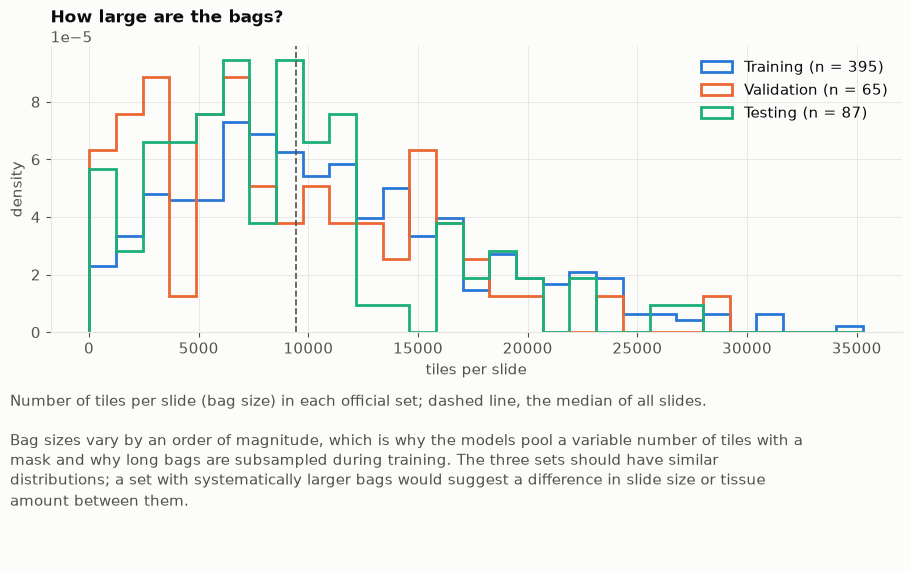

In [7]:
# STEP 1: Tiles per slide by set
# TODO: review
bag_sizes = plot_bag_sizes(data)

### 3.4 Class weights
The classes are imbalanced (see `00_data_visualization.ipynb`), so a loss without weights favours the frequent classes. Weights are computed from the slides that fit the model in each fold only (in the cross-validation of section 5, the early-stopping slides, the held-out fold and the Testing slides do not enter them), so that nothing about the evaluation slides enters training. The table below shows the weights of the official Training slides as an illustration; every fold recomputes them from its own fit slides. Two rules are compared in section 5.1 against no weighting: inverse frequency (every class contributes equally) and its square root (a milder correction).

In [8]:
# STEP 1: Weights per class from the Training counts, for each rule
weights = pd.DataFrame({m: training_class_weights(data, m).numpy() for m in ('sqrt', 'inverse')}, index=classes)
weights.insert(0, 'n_train', (data['table'][data['table']['set'] == 'Training']['label'].astype(str).value_counts().reindex(classes)).to_numpy())
weights.round(3)

,n_train,sqrt,inverse
N,27,1.516,2.090
PB,120,0.719,0.470
UDH,56,1.053,1.008
FEA,24,1.608,2.351
ADH,28,1.489,2.015
DCIS,40,1.245,1.411
IC,100,0.788,0.564


## 4. Models

### 4.1 Gated attention multiple-instance model (ABMIL)
Each tile embedding $h_k$ is first projected by a shared layer. A gated attention network scores every tile, $a_k = \mathrm{softmax}_k\big(w^\top[\tanh(V h_k)\odot\mathrm{sigm}(U h_k)]\big)$, the scores are normalised over the real tiles of the slide (padding is masked), and the slide vector is the attention-weighted sum $z=\sum_k a_k h_k$, which a linear layer maps to the class scores. The model can therefore concentrate on the few tiles that carry the diagnosis and ignore the rest, and its attention weights can be inspected (section 7). The number of outputs equals the number of classes in the label sheet. The mean-pool linear model of `utils/mil_models.py` (the mean of the tile embeddings classified by one linear layer) is not part of this run; adding `'linear'` to `MODELS` in section 2 brings it back as a reference.

### 4.2 CLAM-MB (clustering-constrained attention, multi-branch)
CLAM-MB (Lu et al., 2021) extends the gated attention network in two ways. First, it has **one attention branch per class**: the gated network outputs a score for every tile and class, normalised over the real tiles separately for each class, $a_{k,c}=\mathrm{softmax}_k(\cdot)$, so that every class $c$ has its own slide vector $z_c=\sum_k a_{k,c}h_k$ and its own linear layer, whose output $\hat y_c$ is the score of that class. A slide is thus described, for each class, by the tiles that speak for that class, instead of by a single weighted average. Second, an **instance-level clustering loss** supervises the attention. For the true class of a training slide, the $k$ tiles with the highest attention of that class's branch are given the pseudo-label 1 and the $k$ tiles with the lowest attention the pseudo-label 0; for every other class, the $k$ tiles with the highest attention of that class's branch are given the pseudo-label 0, because they should not be evidence for a class that the slide does not have. A small classifier per class is trained on these pseudo-labels, which pushes the shared projection to separate the tiles that the attention selects. The training loss is $\lambda\,\mathcal{L}_{\mathrm{slide}}+(1-\lambda)\,\mathcal{L}_{\mathrm{instance}}$, with $\lambda$ = `bag_weight` and $k$ = `k_sample` (set in `MODEL_ARGS`). The slide loss is the class-weighted cross-entropy used for the other model and the instance loss is unweighted.

The pseudo-labels are derived from the model's own attention and are not tile ground truth; they can reinforce an early attention error, and the weak slide labels of this data set (a slide label is its highest-grade region) apply to them as well. The comparison with ABMIL therefore measures whether this additional supervision helps on these data, which is not guaranteed. In section 7 the attention of CLAM-MB is that of the branch of the predicted class.

**Reference.** Lu, M. Y., Williamson, D. F. K., Chen, T. Y., Chen, R. J., Barbieri, M. and Mahmood, F. (2021), Data-efficient and weakly supervised computational pathology on whole-slide images, *Nature Biomedical Engineering* 5, 555-570.


In [9]:
# STEP 1: Build the models and compare their size
for name in MODELS:
    model = build_model(name, data['dim'], len(classes), **MODEL_ARGS.get(name, {}))
    print(f'{name:>8}: {sum(p.numel() for p in model.parameters()):>9,} parameters, {len(classes)} outputs')


   abmil: 1,053,448 parameters, 7 outputs
 clam_mb: 1,062,172 parameters, 7 outputs


## 5. Training

### 5.0 Cross-validation folds
The official Validation set has few slides, and some classes have only a handful, so choices made on it alone (the loss weighting, the regularisation, the epoch at which to stop) are noisy. Instead, the official Training and Validation slides are pooled and split into `N_FOLDS` folds that are **grouped by patient** (all slides of a patient are in the same part, because the slides of one patient are not independent; the one patient with slides in both official sets no longer leaks) and **stratified by class** (every fold has about the same class mix). The Testing slides belong to no fold and are first used in section 6.

Every fold defines three parts: the *held-out* slides, which are scored after training and never used for fitting or stopping; the *early-stopping* slides (about a fifth of the remaining slides, chosen with the same patient-grouped stratification), on which the epoch is selected as before (best macro F1, patience `PATIENCE`); and the *fit* slides, on which the model is trained and from which its class weights are computed. Choosing the epoch on slides that are disjoint from the held-out fold keeps the held-out score free of the early-stopping bias. The table shows the composition of the held-out part of every fold. The code checks that every pool slide is held out exactly once, that no patient is shared between the parts of a fold and that no Testing slide is present.


In [10]:
# STEP 1: Patient-grouped, class-stratified folds over the Training and Validation slides (the Testing slides are not part of any fold)
folds = make_cv_folds(data['table'], N_FOLDS, SEED)

# STEP 2: Size and class mix of the held-out part of every fold
fold_summary(folds, classes)


,fold,fit,early stopping,held out,held-out patients,N,PB,UDH,FEA,ADH,DCIS,IC
0,0,293,74,93,34,8,26,13,6,7,10,23
1,1,294,74,92,29,8,26,13,6,7,9,23
2,2,294,74,92,32,7,27,13,6,7,10,22
3,3,294,75,91,32,7,26,13,6,7,10,22
4,4,294,74,92,31,7,26,13,6,8,10,22


### 5.1 Choice of the loss weighting (cross-validation)
Trains the attention model (gated ABMIL) once on each fold with no weights, square-root weights and inverse-frequency weights, the class weights being computed from the fit slides of the fold. The options are compared by the macro F1 of the *out-of-fold* predictions, that is, the held-out predictions of all folds pooled into one prediction per slide of the pool; the table also gives the balanced accuracy, the log-loss and the spread of the macro F1 over folds. Macro F1 gives every class the same weight and is therefore the appropriate criterion under imbalance. The option with the highest pooled macro F1 is used for the final models of both architectures (it is chosen with the attention model and not tuned again for CLAM-MB). The same folds select and score, so the pooled scores of the chosen option are slightly optimistic; differences smaller than the spread over folds should not be over-interpreted, and the Testing set, which is the unbiased estimate, is not touched.


In [11]:
# STEP 1: Compare the weightings by cross-validation (ABMIL, one run per fold)
t0 = time()
ablation = cv_compare('abmil', data, folds, DEVICE, [{'weighting': w} for w in ('none', 'sqrt', 'inverse')], seed=SEED, **TRAIN_ARGS)
WEIGHTING = ablation.loc[0, 'weighting']
print(f'Selected weighting: {WEIGHTING}  ({time() - t0:.0f} s)')
ablation.round(3)


CV abmil:   0%|          | 0/3 [00:00<?, ?it/s]

Selected weighting: none  (333 s)


,model,weighting,oof_macro_f1,oof_balanced_accuracy,oof_log_loss,tier_accuracy,tier_macro_f1,fold_macro_f1_mean,fold_macro_f1_sd,best_epoch_mean,epochs_run_mean,train_loss,stop_loss,loss_gap
0,abmil,none,0.415,0.420,1.309,0.807,0.714,0.406,0.042,11.2,16.2,0.459,1.231,0.771
1,abmil,inverse,0.402,0.410,1.403,0.765,0.685,0.400,0.038,10.4,15.4,0.624,1.213,0.590
2,abmil,sqrt,0.382,0.387,1.297,0.802,0.718,0.384,0.054,9.8,14.8,0.607,1.196,0.589


### 5.2 Choice of the regularisation (cross-validation)
The fit slides are few relative to the capacity of the models, and the slide labels are weak, so a model can fit the fit slides, and the noise in their labels, long before the performance on unseen slides stops improving. Three measures limit this, and their values are chosen by cross-validation: **dropout** (applied after the projection and inside the attention branches), **weight decay** (the decoupled penalty on the size of the weights in AdamW; Loshchilov and Hutter, 2019) and **tile dropout** (a fraction of the tiles of every training bag is removed at random in every epoch, so that the model cannot depend on a few particular tiles; the held-out, early-stopping and Testing slides always keep every tile). In addition, the training stops when the macro F1 on the early-stopping slides has not improved for `PATIENCE` epochs and the weights of the best epoch are restored.

Every combination of the values in `DROPOUTS`, `WEIGHT_DECAYS` and `TILE_DROPOUTS` is trained once on each fold for each model, with the loss weighting of section 5.1. The table gives, per combination, the pooled out-of-fold macro F1, balanced accuracy and log-loss, the accuracy and macro F1 of the three clinical tiers, the mean and standard deviation over folds of the held-out macro F1, the mean epoch of the best result and, as a direct measure of overfitting, the training and the early-stopping loss at that epoch and their difference. The training loss is class-weighted and is computed with dropout active, whereas the early-stopping loss is unweighted, so the difference is informative when rows are compared and not as an absolute value. The first row of each table (highest pooled macro F1; ties: lower log-loss) is used for the final models of that architecture. With the default values, the setting used before the regularisation was tuned (dropout 0.25, weight decay 0.01, no tile dropout) is one of the rows, so the table also shows the effect of the new measures. Differences smaller than the spread over folds should not be over-interpreted. Regularisation reduces overfitting but cannot remove it entirely; the curves in section 5.6 show what remains. The Testing set is not touched.

**Reference.** Loshchilov, I. and Hutter, F. (2019), Decoupled weight decay regularization, *ICLR*.


In [ ]:
# STEP 1: Every combination of the three regularisers, one run per fold, for every model (cross-validation on the pool)
GRID = regularisation_grid(DROPOUTS, WEIGHT_DECAYS, TILE_DROPOUTS)
regularisation, BEST_REG = {}, {}
for name in MODELS:
    t0 = time()
    regularisation[name] = cv_compare(name, data, folds, DEVICE, GRID, weighting=WEIGHTING, seed=SEED, **{**TRAIN_ARGS, **MODEL_ARGS.get(name, {})})
    BEST_REG[name] = {k: float(regularisation[name].loc[0, k]) for k in ('dropout', 'weight_decay', 'tile_dropout')}
    print(f'{name}: {len(GRID)} combinations x {len(folds)} folds ({time() - t0:.0f} s); selected {BEST_REG[name]}')

# STEP 2: The tables (the first row of each model is selected)
pd.concat(regularisation.values()).round(3)


CV abmil:   0%|          | 0/12 [00:00<?, ?it/s]

abmil: 12 combinations x 5 folds (1495 s); selected {'dropout': 0.25, 'weight_decay': 0.01, 'tile_dropout': 0.0}


CV clam_mb:   0%|          | 0/12 [00:00<?, ?it/s]

### 5.3 Coarse auxiliary loss (cross-validation)
The seven classes form three clinical tiers that matter for decisions: benign (N, PB, UDH), atypical (FEA, ADH) and malignant (DCIS, IC). Most confusions between neighbouring grades stay inside a tier or cross only to an adjacent one, and the use of the hierarchy of coarse and fine labels has been proposed to improve the fine-grained classification of BRACS slides (the HMIL method, arXiv:2411.07660). Here the probability of a tier is the sum of the probabilities of its classes, and the coarse loss is the negative log-likelihood of the true tier under these tier probabilities, weighted for each tier by the mean class weight of the fit slides in the tier. The training loss is $(1-\mu)\,\mathcal{L}_{\mathrm{fine}}+\mu\,\mathcal{L}_{\mathrm{coarse}}$, where $\mu$ is `coarse_weight` and 0 gives the loss of the previous sections. No additional label is needed, because the tier follows from the class. The coarse loss rewards probability in the correct tier even when the exact class is wrong, which is the most frequent error.

The values in `COARSE_WEIGHTS` are compared by cross-validation for each model, with the loss weighting and regularisation selected before; the table gives, next to the seven-class measures, the accuracy and the macro F1 of the three tiers. The first row of each model is used for the final models. Other components of HMIL (a supervised contrastive loss, the alignment of class-wise attention across the hierarchy, a schedule that decreases the coarse weight) are not used here.


In [ ]:
# STEP 1: The coarse loss weights, one run per fold, for every model (selected weighting and regularisation)
coarse, BEST_COARSE = {}, {}
for name in MODELS:
    t0 = time()
    settings = [{**BEST_REG[name], 'coarse_weight': w} for w in COARSE_WEIGHTS]
    coarse[name] = cv_compare(name, data, folds, DEVICE, settings, weighting=WEIGHTING, seed=SEED, **{**TRAIN_ARGS, **MODEL_ARGS.get(name, {})})
    BEST_COARSE[name] = float(coarse[name].loc[0, 'coarse_weight'])
    print(f'{name}: {len(settings)} weights x {len(folds)} folds ({time() - t0:.0f} s); selected coarse weight {BEST_COARSE[name]}')

# STEP 2: The tables (the first row of each model is selected)
pd.concat(coarse.values())[['model', 'coarse_weight', 'oof_macro_f1', 'oof_balanced_accuracy', 'tier_accuracy', 'tier_macro_f1', 'fold_macro_f1_mean', 'fold_macro_f1_sd', 'loss_gap']].round(3)


### 5.4 Final training: the fold models
The final models are the fold models of the selected setting (loss weighting, dropout, weight decay, tile dropout, coarse weight), trained with `N_REPEATS_FINAL` repeats of every fold (a different seed for each repeat) for each model in `MODELS`. Each is trained on the fit slides of its fold, with the epoch chosen on its early-stopping slides and with its own feature scaler, so none of them has seen the held-out slides of its fold or any Testing slide. Together they form an ensemble per architecture; section 6 averages their probabilities.


In [ ]:
# STEP 1: The fold models of the selected setting, for every model
cv, runs = {}, {}
for name in MODELS:
    t0 = time()
    setting = {**BEST_REG[name], 'coarse_weight': BEST_COARSE[name]}
    cv[name] = cross_validate(name, data, folds, DEVICE, WEIGHTING, N_REPEATS_FINAL, SEED, **{**TRAIN_ARGS, **MODEL_ARGS.get(name, {}), **setting})
    runs[name] = cv[name]['runs']
    per_fold = cv[name]['per_fold'].groupby('fold')['macro_f1'].mean()
    print(f'{name:>8}: held-out macro F1 {per_fold.mean():.3f} ± {per_fold.std(ddof=1) if len(per_fold) > 1 else 0:.3f} over {len(per_fold)} folds  ({len(runs[name])} models, {time() - t0:.0f} s)')


### 5.5 Out-of-fold performance on the pool
The held-out predictions of the fold models on the Training and Validation slides, one prediction per slide (averaged over the repeats), with the 95% patient-bootstrap intervals of the main measures and the confusion matrices. These estimates rest on about five times more slides than the official Validation set and are therefore more stable than a single small set, but the setting was selected on the same folds, so they are slightly optimistic; the Testing set in section 6 is the unbiased estimate.


In [ ]:
# STEP 1: Pooled out-of-fold probabilities, measures and bootstrap intervals (patients are resampled with all of their slides)
y_oof, patients_oof = cv[MODELS[0]]['y'], cv[MODELS[0]]['patients']
oof_proba = {name: c['proba'] for name, c in cv.items()}
oof_eval = {name: evaluate_predictions(y_oof, p, classes) for name, p in oof_proba.items()}
oof_intervals = {name: patient_bootstrap(y_oof, oof_proba[name], patients_oof, N_BOOT, SEED) for name in oof_proba}

# STEP 2: One table (value [95% interval]) and the confusion matrices
pd.DataFrame({name: {m: f"{r['point']:.3f} [{r['low']:.3f}, {r['high']:.3f}]" for m, r in oof_intervals[name]['ci'].iterrows()} for name in MODELS})
oof_confusion = plot_confusion({name: e['confusion'] for name, e in oof_eval.items()}, title='out-of-fold predictions on the Training and Validation slides')


### 5.6 Training curves
Training and early-stopping loss and early-stopping macro F1 per epoch of the fold models, averaged over folds and repeats. They show whether the models have converged, how much they overfit and which epoch was selected. The gap between the training and the early-stopping loss, and the epoch after which the early-stopping macro F1 stops improving, are the signs of overfitting to inspect; the curves of the final models can be compared with the tables of sections 5.2 and 5.3.


In [ ]:
# STEP 1: Curves of every model (mean over the fold models, band = one standard deviation)
curves = plot_training_curves({name: [r['history'] for r in rs] for name, rs in runs.items()})


## 6. Evaluation on the Testing set
From here on the Testing labels are used, once. No setting is changed after looking at these results; any new choice would have to be made by cross-validation on the Training and Validation slides and the evaluation repeated.

### 6.1 Predictions and metrics
Each model predicts the Testing slides with every tile of every slide, and the probabilities of the fold models (all folds and repeats of the selected setting) are averaged. Reported measures (all computed from the class probabilities, one-vs-rest where a measure is binary):
- **Accuracy** and **balanced accuracy** (mean recall per class; insensitive to class frequency).
- **F1** per class, and its **macro** average (every class counts equally) and **weighted** average (weighted by class frequency).
- **AUROC** (area under the ROC curve; the probability that a slide of a class is ranked above a slide of another class) and **average precision** (area under the precision-recall curve), per class and macro-averaged.
- **Quadratic-weighted Cohen's kappa**, which penalises errors by their distance on the ordered scale of classes, and the **Matthews correlation coefficient**.
- **Log-loss**, **Brier score** and **expected calibration error** for the quality of the probabilities.

Intervals are 95% percentile intervals of a **patient-level bootstrap**: patients, with all of their slides, are resampled, because the slides of one patient are not independent. Classes that are missing from a resample are left out of that resample's macro averages.

In [ ]:
# STEP 1: The Testing slides (first use of the Testing labels)
test = data['table'][data['table']['set'] == 'Testing'].reset_index(drop=True)
test_slides = test['slide'].tolist()
y_test = np.array([classes.index(str(l)) for l in test['label']])
patients = test['patient'].to_numpy()

# STEP 2: Fold-ensemble probabilities of every model (with the attention of the models that have one)
predictions = {name: predict_ensemble(rs, data, test_slides, DEVICE, attention=(name != 'linear')) for name, rs in runs.items()}
proba = {name: p['proba'] for name, p in predictions.items()}

# STEP 3: All measures, bootstrap intervals and single-model results
evaluations = {name: evaluate_predictions(y_test, proba[name], classes) for name in proba}
intervals = {name: patient_bootstrap(y_test, proba[name], patients, N_BOOT, SEED, per_class=True) for name in proba}
per_seed = {name: per_seed_metrics(y_test, predictions[name]['per_seed']) for name in proba}
paired = paired_bootstrap(y_test, proba[MODELS[1]], proba[MODELS[0]], patients, N_BOOT, SEED)   # second model minus first

# STEP 4: One table with every measure (ensemble value [95% interval]; single models as mean ± sd)
results = results_table(evaluations, {n: intervals[n]['ci'] for n in intervals}, per_seed)
results

### 6.2 Confusion matrices
Rows are the true classes and columns the predicted classes. The diagonal is correct classifications; mass next to the diagonal is confusion between neighbouring grades, which is expected from the graded nature of the classes and from the known disagreement between pathologists.

In [ ]:
# STEP 1: Confusion matrix of each model on the Testing set
confusion = plot_confusion({name: e['confusion'] for name, e in evaluations.items()})

### 6.3 ROC and precision-recall curves
One-vs-rest curves for every class. The ROC curve and its area (AUROC) describe how well a class is ranked above the others independently of the decision threshold and of the class frequency; the precision-recall curve and the average precision depend on the class frequency, so they are shown next to it for the imbalanced classes.

In [ ]:
# STEP 1: ROC (top) and precision-recall (bottom) curves of every class and model
curves_roc_pr = plot_roc_pr(y_test, proba, classes)

### 6.4 Per-class results
F1 and AUROC of each class with patient-bootstrap intervals, and the number of Testing slides of each class. The intervals show how little can be concluded for the small classes.

In [ ]:
# STEP 1: F1 and AUROC per class with 95% intervals
per_class = plot_per_class({name: e['per_class'] for name, e in evaluations.items()}, intervals)

### 6.5 Calibration
Whether the probabilities of the models can be read as frequencies. The class weighting shifts probability towards the rare classes on purpose, so calibration with respect to the true class frequencies is not expected; the diagram shows how large the effect is and whether the models are overconfident.

In [ ]:
# STEP 1: Reliability diagram and confidence histogram
calibration = plot_calibration(y_test, proba)

### 6.6 Clinical summaries
The seven-class probabilities are summed into two clinically motivated views, without any new training: three tiers (benign: N, PB, UDH; atypical: FEA, ADH; malignant: DCIS, IC) and cancer (DCIS or IC) against everything else. The second is the clinically decisive boundary; the sensitivity at 90% specificity is reported as an example of an operating point, which for any application would be chosen on the Validation set. Both models are shown: the confusion matrix of each model for the three tiers and for cancer or not, and their ROC and precision-recall curves in the same panels. For cancer or not, a slide is called cancer when the summed probability of DCIS and IC is at least 0.5; this threshold is fixed in advance and not tuned on the Testing set. The class weighting and the prevalence of cancer in the Testing set shift the probabilities, so 0.5 is not necessarily a suitable operating point, and the sensitivity, specificity and predictive values at this threshold describe the models as trained and not a recommended setting.

In [ ]:
# STEP 1: Confusion matrices (three tiers; cancer or not at a fixed threshold of 0.5), one per model, and the ROC and precision-recall curves for cancer
clinical = plot_clinical_views(y_test, proba, classes)

# STEP 2: The numbers behind the figure, per model
pd.DataFrame({name: {
    'tier accuracy': v['tiers']['summary']['accuracy'], 'tier balanced accuracy': v['tiers']['summary']['balanced_accuracy'], 'tier macro F1': v['tiers']['summary']['macro_f1'],
    'cancer AUROC': v['cancer']['auroc'], 'cancer AP': v['cancer']['ap'], 'cancer sensitivity at 90% specificity': v['cancer']['sensitivity_at_specificity'],
    f"cancer sensitivity at threshold {v['cancer']['threshold']:g}": v['cancer']['sensitivity'], f"cancer specificity at threshold {v['cancer']['threshold']:g}": v['cancer']['specificity'],
    f"cancer precision at threshold {v['cancer']['threshold']:g}": v['cancer']['ppv'], f"cancer NPV at threshold {v['cancer']['threshold']:g}": v['cancer']['npv']}
    for name, v in clinical['views'].items()}).round(3)


### 6.7 Comparison of the two models
The headline measures of both models with their intervals and single models, and the paired difference (CLAM-MB minus gated ABMIL, the second model of `MODELS` minus the first) estimated on the same bootstrap resamples. An interval for the difference that contains zero means that the data do not show a difference between the models.

In [ ]:
# STEP 1: Measures with intervals, and the paired difference
comparison = plot_model_comparison({n: intervals[n]['ci'] for n in intervals}, per_seed, paired, MODELS[1], MODELS[0])
paired.round(3)

## 7. Interpretation: attention over the tiles
The attention weights of the two models show which tiles they rely on. The slides are chosen once, from the predictions of the first model: two correctly classified Testing slides (the lowest and the highest class, with the highest confidence) and the most confident error. For each model, the weight of every tile is drawn on the slide and the six tiles with the highest weight are shown; the titles give the prediction of that model, which can differ between the models. For CLAM-MB the weights are those of the attention branch of the predicted class. The two sets of weights are not on a common scale (each sums to 1 over the slide, and CLAM-MB normalises separately for each class), so only where the weight is concentrated should be compared, not its value. Attention is not an explanation in the causal sense: it shows where a model looks, not why, and tiles with artefacts or staining differences can receive attention for reasons unrelated to the lesion.


In [ ]:
# STEP 1: The slides to show, chosen from the first model: the most confident correct slide of the first and the last class, and the most confident error
first = predictions_table(test, classes, proba[MODELS[0]])
correct, wrong = first[first['true'] == first['pred']], first[first['true'] != first['pred']]
shown = [correct[correct['true'] == c].sort_values('confidence')['slide'].iloc[-1] for c in (classes[0], classes[-1]) if (correct['true'] == c).any()]
shown += wrong.sort_values('confidence')['slide'].tolist()[-1:]

# STEP 2: Attention maps and top tiles of every model on those slides (tiles are shown when the slides are available in DATA_DIR)
attention_figures = {}
for name in MODELS:
    pred_table = predictions_table(test, classes, proba[name])
    attention = dict(zip(test_slides, predictions[name]['attention']))
    attention_figures[name] = plot_attention(shown, data, attention, pred_table, DATA_DIR, model=name)


## 8. Summary and saving the classifier

### 8.1 Main results
The main measures of the two models (gated ABMIL and CLAM-MB) on the Testing set, side by side, as ensemble value with its 95% interval.

In [ ]:
# STEP 1: Headline measures of both models
results.loc[['accuracy', 'balanced_accuracy', 'macro_f1', 'weighted_f1', 'macro_auroc', 'macro_ap', 'quadratic_kappa', 'mcc', 'top2_accuracy', 'ece'], list(MODELS)]

### 8.2 Model decision
Describes the classifier that is saved in 8.3, before it is written: the architecture as a graph of the forward pass, the location and use of the file, the hyperparameters and training setup, and the rule of selection. The selected model is the fold model with the highest macro F1 on the early-stopping slides of its fold among both architectures, all folds and all repeats (`select_best_run`); the Testing set plays no part in this choice, which would otherwise bias the test result. The same function is used by the saving step, so the model described here is the model in the file. The configuration of the run is assembled here and reused in 8.3.

In [ ]:
# STEP 1: Everything needed to reproduce and to reuse the run
config = dict(
    seed=SEED, n_folds=N_FOLDS, n_repeats_final=N_REPEATS_FINAL, models=list(MODELS), model_args=MODEL_ARGS, classes=classes, weighting=WEIGHTING, train_args=TRAIN_ARGS, patience=PATIENCE, regularisation=BEST_REG, coarse_weights=BEST_COARSE, coarse_weight_grid=COARSE_WEIGHTS, regularisation_grid=dict(dropouts=DROPOUTS, weight_decays=WEIGHT_DECAYS, tile_dropouts=TILE_DROPOUTS), n_boot=N_BOOT,
    features_dir=str(FEATURES_DIR), model_name=MODEL_NAME, tile_params=data['tile_params'], device=device_description(DEVICE),
    versions=dict(torch=torch.__version__, sklearn=sklearn.__version__, numpy=np.__version__, pandas=pd.__version__),
    n_slides={s: int((data['table']['set'] == s).sum()) for s in ('Training', 'Validation', 'Testing')}, dropped_slides=data['missing'],
    best_epochs={n: [r['best_epoch'] for r in rs] for n, rs in runs.items()},
)

# STEP 2: The selected model, its architecture and its specification
best = select_best_run(runs)
decision_figure = plot_model_decision(best, config, MODEL_DIR)

### 8.3 Saving the best classifier
Saves the classifier selected in 8.2 to `classifier/classifier_model_<date-time>.pt` (set `SAVE_BEST_MODEL = False` to save nothing). It is the fold model with the highest macro F1 on its early-stopping slides among both models, all folds and all repeats; the Testing set plays no part in this choice, which would otherwise bias the test result. The file contains the weights, the class names of the label sheet (the output order of the model), the feature scaler fitted on the Training slides, the architecture settings, the Validation result and the configuration of the run (seeds, training arguments, selected weighting, tiling of the features, versions, device). `utils.mil_train.load_classifier` loads it again. The reported test results are those of the seed ensemble; the saved file is one model of it.

In [ ]:
# STEP 1: Save the best classifier (chosen on the early-stopping slides of the folds, never on the Testing set); nothing else is written
if SAVE_BEST_MODEL:
    model_path = save_best_model(runs, MODEL_DIR, config)
    print('Best classifier saved to', model_path.resolve())
else:
    print('SAVE_BEST_MODEL is False: nothing was written.')